In [1]:
#Import mathematical libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
#Create first financial dataset
prices = pd.Series(
    [100, 110, 99, 108],
    name="Price"
)

prices

0    100
1    110
2     99
3    108
Name: Price, dtype: int64

In [4]:
#Calculate simple returns
simple_returns = prices / prices.shift(1) - 1

simple_returns

0         NaN
1    0.100000
2   -0.100000
3    0.090909
Name: Price, dtype: float64

In [5]:
#Calculate logarithmic returns
log_returns = np.log(
    prices / prices.shift(1)
)

log_returns

0         NaN
1    0.095310
2   -0.105361
3    0.087011
Name: Price, dtype: float64

In [6]:
#Create a research table
results = pd.DataFrame({
    "Price": prices,
    "Simple Return": simple_returns,
    "Log Return": log_returns
})

results

,Price,Simple Return,Log Return
0,100,NaN,NaN
1,110,0.100000,0.095310
2,99,-0.100000,-0.105361
3,108,0.090909,0.087011


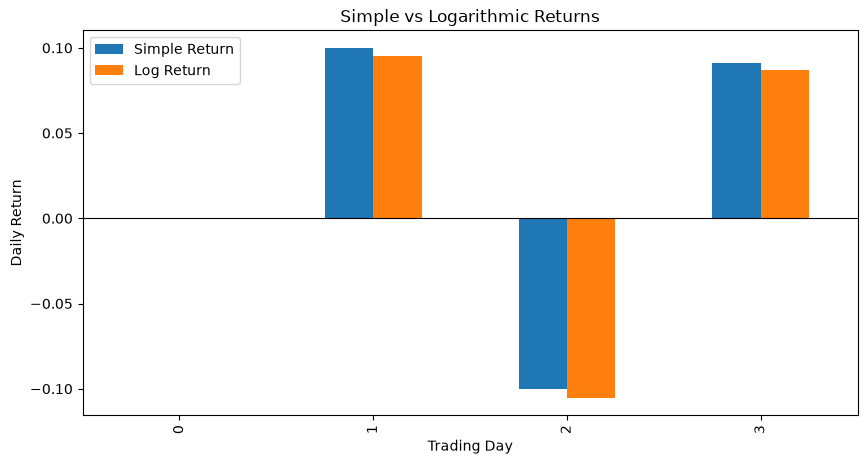

In [7]:
#Visualize the results
results[["Simple Return", "Log Return"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Simple vs Logarithmic Returns")
plt.ylabel("Daily Return")
plt.xlabel("Trading Day")
plt.axhline(0, color="black", linewidth=0.8)
plt.show()

In [16]:
#Cumulative simple return using the first and last prices.

cumulative_simple_return_1 = prices.iloc[-1] / prices.iloc[0] - 1

print(f"Cumulative Simple Return: {cumulative_simple_return_1:.2%}")

Cumulative Simple Return: 8.00%


In [19]:
#Cumulative simple return using the product of daily gross returns.

cumulative_simple_return_2 = (1 + results["Simple Return"]).prod() - 1

print(f"Cumulative Simple Return: {cumulative_simple_return_2:.2%}")


Cumulative Simple Return: 8.00%


In [24]:
#Cumulative log return using the sum of daily log returns.

cumulative_log_return = (results["Log Return"]).sum()

print(f"Cumulative Log Return: {cumulative_log_return:.4%}")

Cumulative Log Return: 7.6961%


In [28]:
# Convert cumulative log return into simple return.

cumulative_simple_return_3 = np.exp(cumulative_log_return)-1

print(f"Cumulative Simple Return: {cumulative_simple_return_3:.2%}")

Cumulative Simple Return: 8.00%


In [29]:
# Validate Method 1 against Method 2

validation_1 = np.isclose(cumulative_simple_return_1,cumulative_simple_return_2)

# Validate Method 1 against Method 3

validation_2 = np.isclose(cumulative_simple_return_1,cumulative_simple_return_3)

# Validate all three methods

print(validation_1 and validation_2)

True


1. Simple returns are multiplicative across time.
2. Logarithmic returns are additive across time.
3. Both methods represent the same investment
   performance when converted appropriately.
4. Identical cumulative returns do not imply
   identical investment risk.
5. A risk-averse investor generally prefers lower
   risk for the same expected return.
6. Historical returns alone are insufficient
   for making investment decisions.